# ComplexHeatmap simple quickstart method

In [5]:
# quick-start guide for plotting a DGE heatmap from a DGE table and a relative expression table via ComplexHeatmap
# full user-guide can be found here: https://jokergoo.github.io/ComplexHeatmap-reference/book/

library(ComplexHeatmap)
library(circlize)

Loading required package: grid

ComplexHeatmap version 2.18.0
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://github.com/jokergoo/ComplexHeatmap
Documentation: http://jokergoo.github.io/ComplexHeatmap-reference

If you use it in published research, please cite either one:
- Gu, Z. Complex Heatmap Visualization. iMeta 2022.
- Gu, Z. Complex heatmaps reveal patterns and correlations in multidimensional 
    genomic data. Bioinformatics 2016.


The new InteractiveComplexHeatmap package can directly export static 
complex heatmaps into an interactive Shiny app with zero effort. Have a try!

This message can be suppressed by:
  suppressPackageStartupMessages(library(ComplexHeatmap))


circlize version 0.4.16
CRAN page: https://cran.r-project.org/package=circlize
Github page: https://github.com/jokergoo/circlize
Documentation: https://jokergoo.github.io/circlize_book/book/

If you use it in published research, please cite:
Gu, Z. circlize implements a

In [1]:
# import normalized counts table (or whatever relative expression data)
# e.g. where the first column is gene name and the remaining columns are relative expression values for each sample in the experiment

norm.counts <- read.csv("251126_Heatmap.csv")
genes <- norm.counts$Gene # save gene names
norm.counts$Gene <- NULL
Annotations <- norm.counts$Annotation # save annotations
norm.counts$Annotation <- NULL
norm.counts <- as.matrix(norm.counts) # convert to numeric matrix
rownames(norm.counts) <- genes # make gene names the row names
rm(genes)
head(norm.counts)
tail(norm.counts)

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Aldoc,10787.778,9271.871,9270.344,10605.977,10235.352,13206.650,12051.384,13356.177
Ier3,2633.038,2254.178,1901.816,2507.514,2970.015,3936.221,3806.419,3813.176
Plet1,39772.060,36394.670,34314.365,39655.688,37560.216,52101.970,48170.418,49070.423
Rcn1,11699.988,10115.076,10313.247,10546.726,11816.283,14308.442,13158.582,14187.431
Kctd14,8954.415,7568.564,8016.528,8461.081,9761.435,11013.189,10721.771,11066.789
Emb,28297.144,25187.991,23488.642,29156.364,34359.983,41384.976,38096.381,40823.543


,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Des,6747.6715,7436.7604,7443.0212,8690.9759,2674.4653,3204.168,2323.6520,1930.41394
Cald1,9729.4953,10262.0872,10621.9891,11049.1763,8778.3439,5871.272,6760.2469,5439.67986
Cavin3,1533.7649,1527.5690,1410.8802,1801.2385,1293.1595,1226.611,1020.3778,768.77703
Palld,2523.4831,2887.8490,2987.7991,3026.5547,2345.2126,2168.498,2128.5511,1645.56405
Actb,42814.9964,42369.7635,41365.1759,43561.5318,33208.8950,27085.980,27783.3468,27041.67892
Npas4,645.4035,566.0792,657.8722,687.3147,189.2555,175.423,157.0562,88.94941


In [2]:
# center and scale the rlog counts table (i.e. produce Z-score expression values across the samples, for each gene)
# note: t() will transpose the matrix
# so, here, we are transposing the matrix, center and scaling with scale(), then transposing back
# the reason for this is that scale() by default wants to scale each column vector (samples here), but we want to scale gene-wise

scaled.norm.counts <- t(scale(t(norm.counts)))

head(scaled.norm.counts)


,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Aldoc,-0.1924454,-1.1322545,-1.133201,-0.3051559,-0.534930229,1.307170,0.5909455,1.399871
Ier3,-0.4386292,-0.9206430,-1.368945,-0.5983304,-0.009901105,1.219380,1.0542355,1.062833
Plet1,-0.3539558,-0.8609487,-1.173231,-0.3714249,-0.685984228,1.496934,0.9067537,1.041857
Rcn1,-0.1878601,-1.1234685,-1.006484,-0.8686561,-0.119208520,1.351967,0.6731793,1.280531
Kctd14,-0.3524283,-1.3470450,-1.025544,-0.7064910,0.226765420,1.125141,0.9159924,1.163609
Emb,-0.6115476,-1.0535027,-1.295059,-0.4894124,0.250263878,1.248842,0.7813798,1.169036


In [3]:
# Export normalized counts file if desired

write.csv(scaled.norm.counts,file="scaled.norm.counts.csv") # keeps the rownames

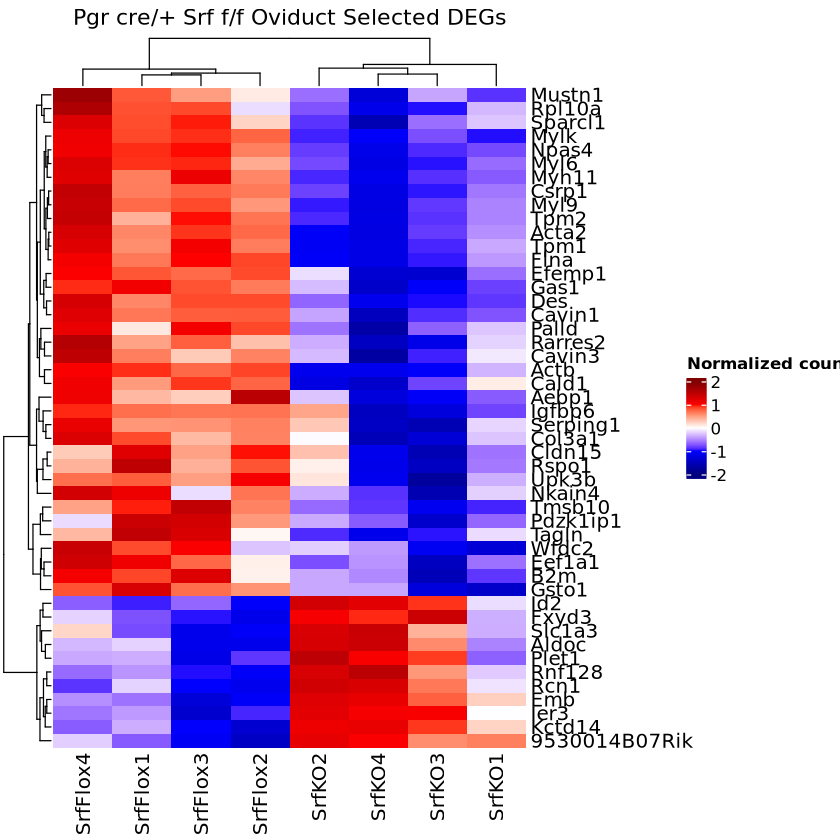

In [6]:
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        clustering_distance_rows = "euclidean", # this is the default method
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected DEGs", # set your own title
        cluster_columns=TRUE)

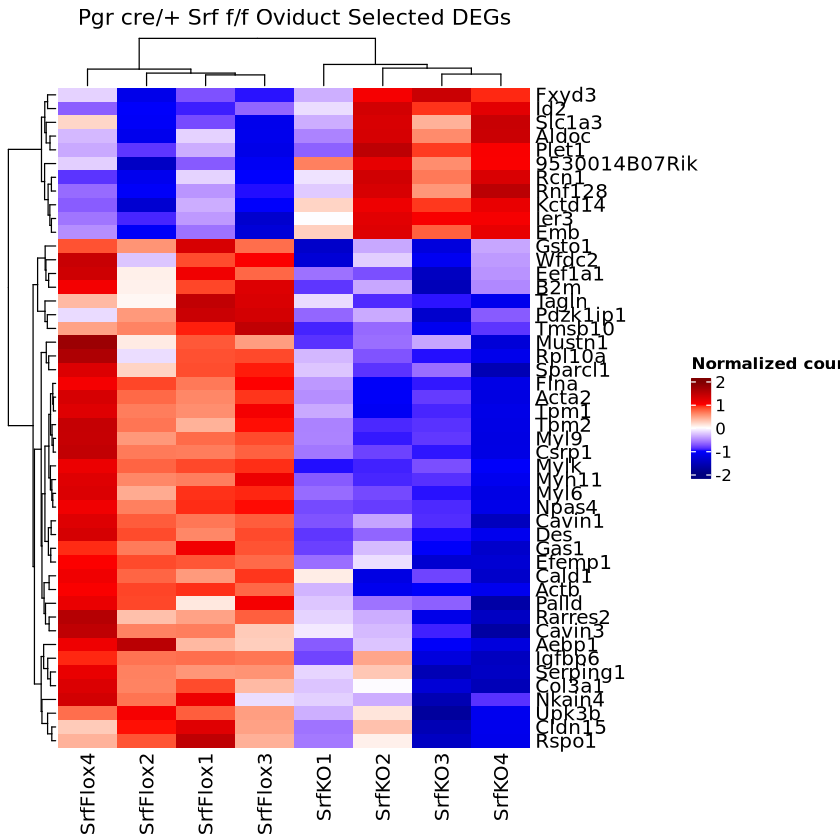

In [7]:
#Cluster but do not reorder dendrograms
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        clustering_distance_rows = "euclidean", # this is the default method
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized count", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected DEGs", # set your own title
        cluster_columns=TRUE,
        row_dend_reorder = FALSE,
        column_dend_reorder = FALSE)


Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


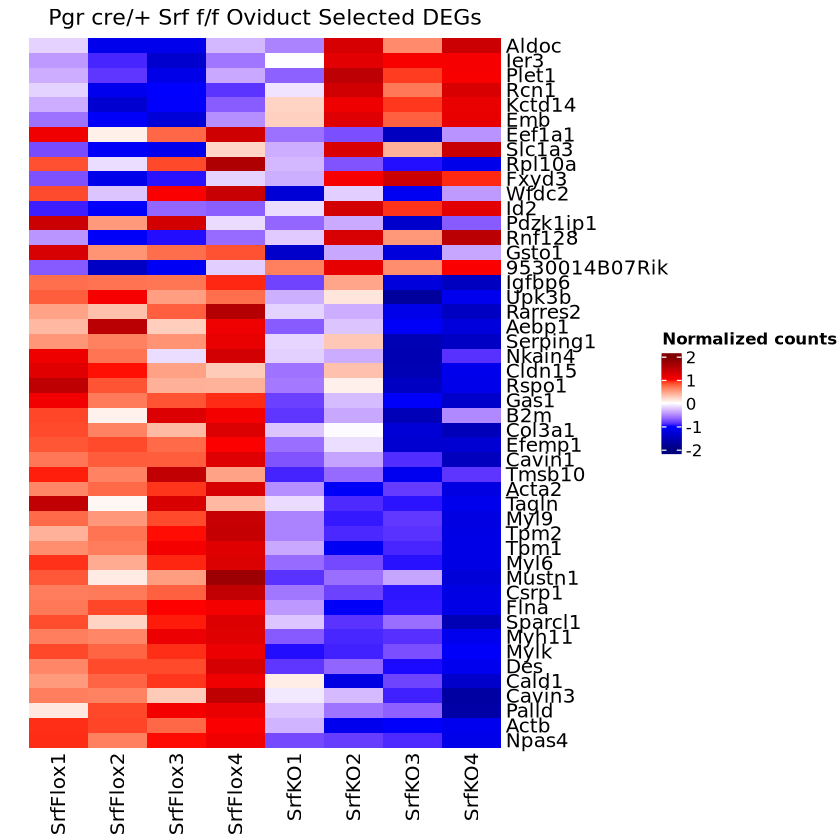

In [8]:
#Stop clustering rows and columns - keep original order 
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


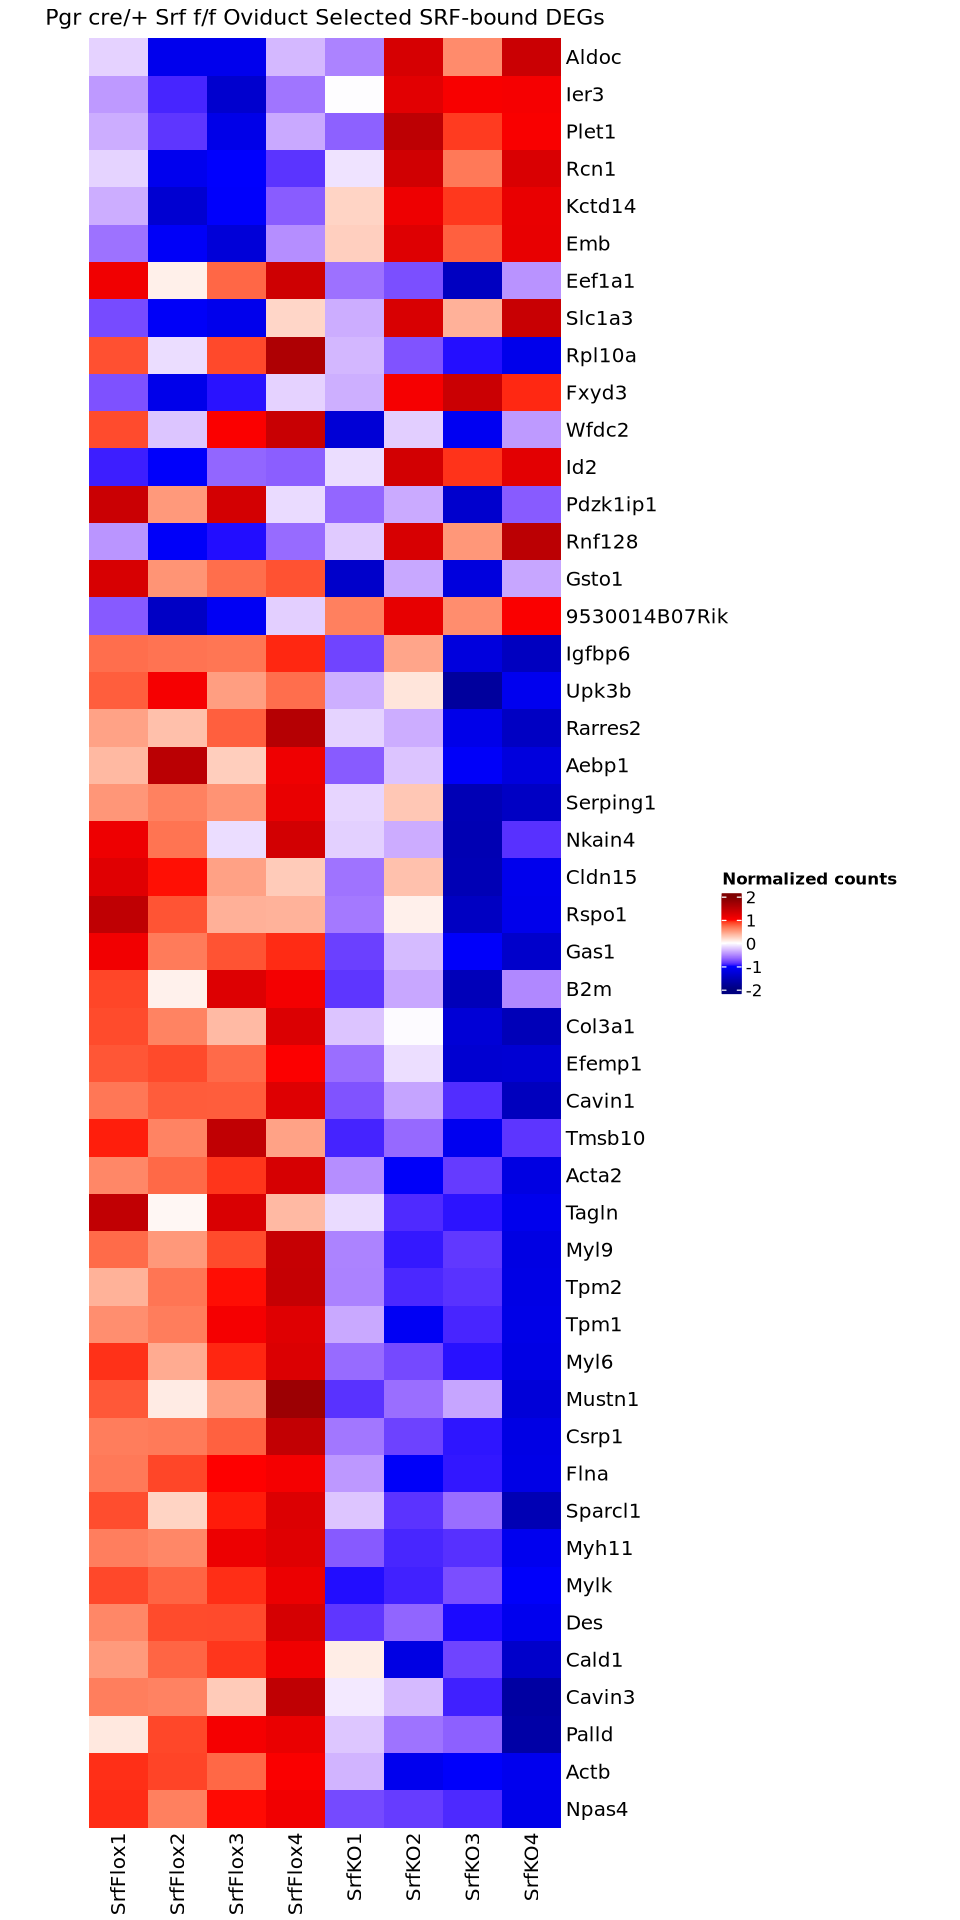

In [10]:
# Adjust plot size
saved <- options(repr.plot.width = 8, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

#Stop clustering rows and columns
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


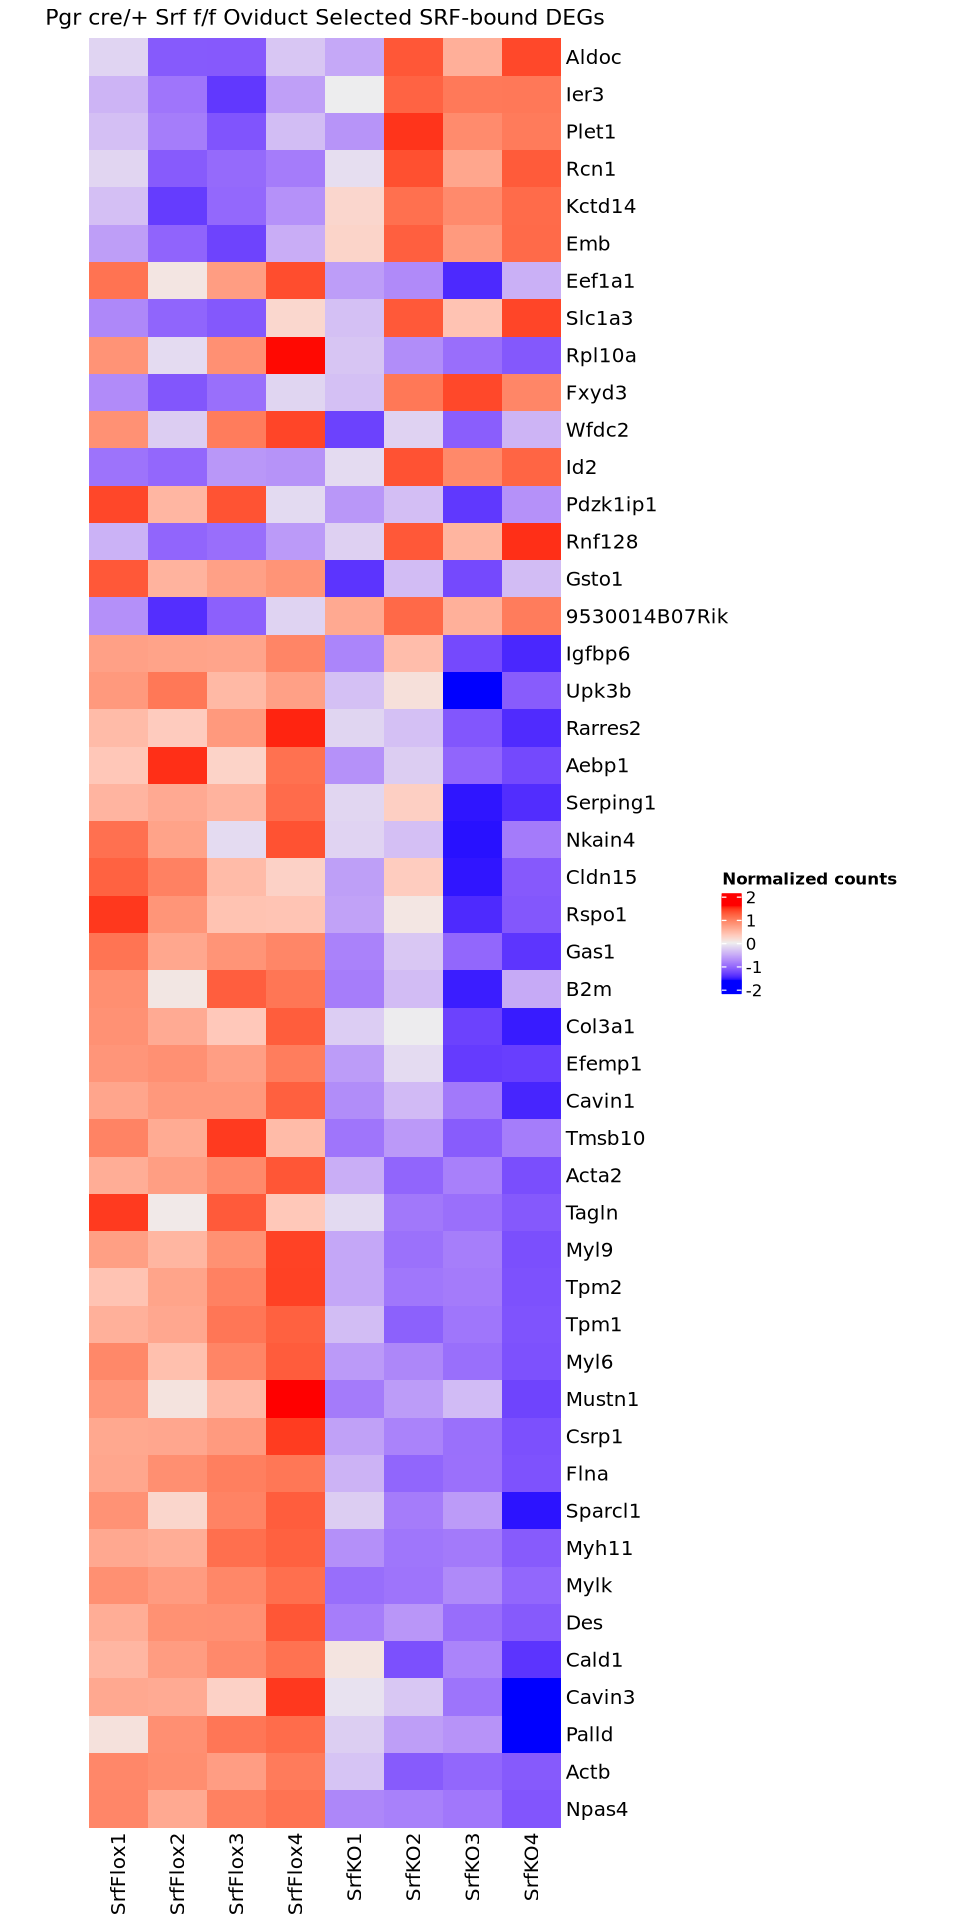

In [11]:
saved <- options(repr.plot.width = 8, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

# Change to default color scheme

# Stop clustering rows and columns
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

options(saved) # restore old settings

In [12]:
# FYI: to add back annotations
scaled.norm.counts.annotated <- cbind(scaled.norm.counts, Annotations)
head(scaled.norm.counts.annotated)

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4,Annotations
Aldoc,-0.192445417007215,-1.13225448148436,-1.13320090104804,-0.305155861164239,-0.534930228634126,1.30717001157509,0.590945548227717,1.39987132953517,secretory (InfAmp)
Ier3,-0.438629217041866,-0.920643004997456,-1.36894467850998,-0.598330446071348,-0.00990110512656306,1.21938007466613,1.05423553782948,1.0628328392516,secretory (InfAmp)
Plet1,-0.353955782447778,-0.860948714480802,-1.17323130754035,-0.371424851080711,-0.685984228039233,1.4969340887209,0.906753742823478,1.0418570520445,secretory (InfAmp)
Rcn1,-0.187860084274614,-1.12346850670781,-1.00648364913052,-0.868656107870347,-0.119208519793361,1.35196651805727,0.673179253007989,1.28053109671139,secretory (InfAmp)
Kctd14,-0.352428269773024,-1.34704501774926,-1.02554404248307,-0.706490983835885,0.226765420194932,1.12514096614714,0.915992435004677,1.16360949249449,secretory (InfAmp)
Emb,-0.611547581927182,-1.05350269209637,-1.29505926190658,-0.489412442555687,0.250263877855893,1.24884204723723,0.781379824629095,1.1690362287636,secretory (InfAmp)


# Alternative ComplexHeatmap method using draw function to add annotations

In [14]:
# Following: https://www.biostars.org/p/286187/#286507
# Load one more package
library(cluster)

In [15]:
# Load and view data
df <- read.csv("251126_Heatmap.csv")
head(df)

,Annotation,Gene,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,secretory (InfAmp),Aldoc,10787.778,9271.871,9270.344,10605.977,10235.352,13206.650,12051.384,13356.177
2,secretory (InfAmp),Ier3,2633.038,2254.178,1901.816,2507.514,2970.015,3936.221,3806.419,3813.176
3,secretory (InfAmp),Plet1,39772.060,36394.670,34314.365,39655.688,37560.216,52101.970,48170.418,49070.423
4,secretory (InfAmp),Rcn1,11699.988,10115.076,10313.247,10546.726,11816.283,14308.442,13158.582,14187.431
5,secretory (InfAmp),Kctd14,8954.415,7568.564,8016.528,8461.081,9761.435,11013.189,10721.771,11066.789
6,secretory (InfAmp),Emb,28297.144,25187.991,23488.642,29156.364,34359.983,41384.976,38096.381,40823.543


In [16]:
# center and scale the rlog counts table (i.e. produce Z-score expression values across the samples, for each gene)
# note: t() will transpose the matrix, and we are specifying that we are only taking the data starting in the 3rd column
# so, here, we are transposing the matrix, center and scaling with scale(), then transposing back
# the reason for this is that scale() by default wants to scale each column vector (samples here), but we want to scale gene-wise

heat <- t(scale(t(df[,3:ncol(df)])))
rownames(heat) <- df$Gene # assign row names as gene names
head(heat) # check our work

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Aldoc,-0.1924454,-1.1322545,-1.133201,-0.3051559,-0.534930229,1.307170,0.5909455,1.399871
Ier3,-0.4386292,-0.9206430,-1.368945,-0.5983304,-0.009901105,1.219380,1.0542355,1.062833
Plet1,-0.3539558,-0.8609487,-1.173231,-0.3714249,-0.685984228,1.496934,0.9067537,1.041857
Rcn1,-0.1878601,-1.1234685,-1.006484,-0.8686561,-0.119208520,1.351967,0.6731793,1.280531
Kctd14,-0.3524283,-1.3470450,-1.025544,-0.7064910,0.226765420,1.125141,0.9159924,1.163609
Emb,-0.6115476,-1.0535027,-1.295059,-0.4894124,0.250263878,1.248842,0.7813798,1.169036


In [17]:
# Export normalized counts file if desired

write.csv(heat,file="heat_scaled.norm.counts.csv") # keeps the rownames

In [18]:
# If you want to adjust the sample order but keep clustering turned off, change column order in the matrix
new_order <- c(4, 3, 1, 2, 5, 6, 7, 8)
heat <- heat[, new_order]
head(heat) # check our work

,SrfFlox4,SrfFlox3,SrfFlox1,SrfFlox2,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Aldoc,-0.3051559,-1.133201,-0.1924454,-1.1322545,-0.534930229,1.307170,0.5909455,1.399871
Ier3,-0.5983304,-1.368945,-0.4386292,-0.9206430,-0.009901105,1.219380,1.0542355,1.062833
Plet1,-0.3714249,-1.173231,-0.3539558,-0.8609487,-0.685984228,1.496934,0.9067537,1.041857
Rcn1,-0.8686561,-1.006484,-0.1878601,-1.1234685,-0.119208520,1.351967,0.6731793,1.280531
Kctd14,-0.7064910,-1.025544,-0.3524283,-1.3470450,0.226765420,1.125141,0.9159924,1.163609
Emb,-0.4894124,-1.295059,-0.6115476,-1.0535027,0.250263878,1.248842,0.7813798,1.169036


# Annotate selected genes

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


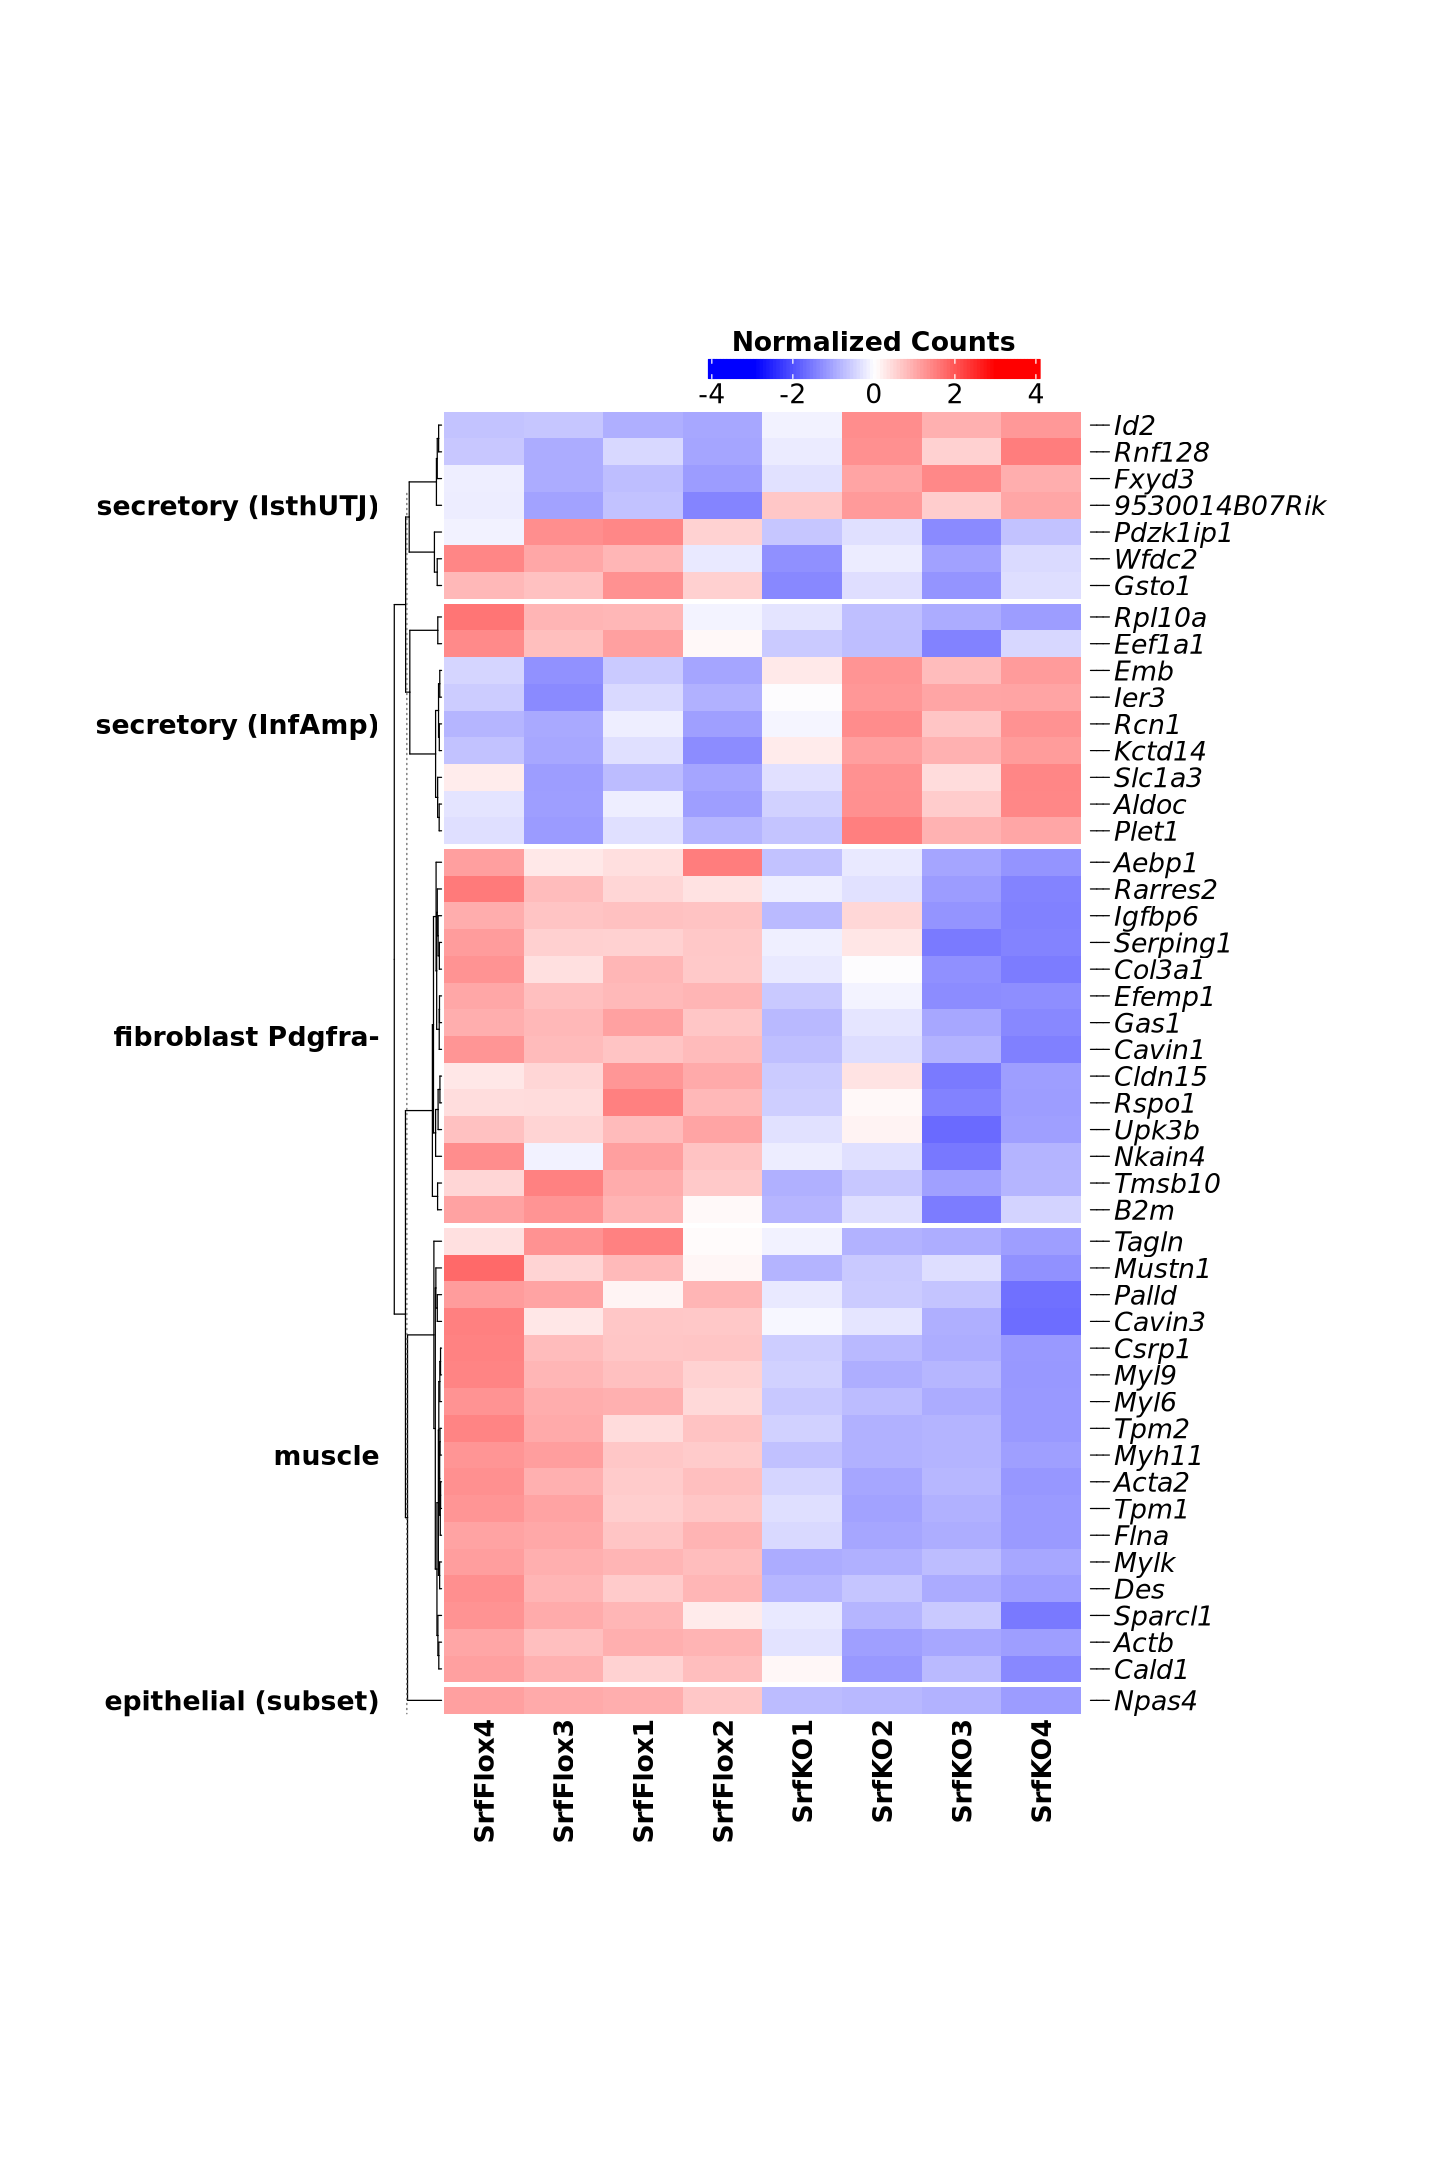

In [24]:
# Draw with right side annotation of specific genes, remove dendrogram
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 12, repr.plot.height = 18) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Aldoc", "Ier3", "Plet1", "Rcn1", "Kctd14", "Emb", "Eef1a1", "Slc1a3", 
                  "Rpl10a", "Fxyd3", "Wfdc2", "Id2", "Pdzk1ip1", "Rnf128", "Gsto1", "9530014B07Rik", 
                  "Igfbp6", "Upk3b", "Rarres2", "Aebp1", "Serping1", "Nkain4", "Cldn15", "Rspo1", "Gas1", "B2m", "Col3a1", "Efemp1", "Cavin1", "Tmsb10", 
                  "Acta2", "Tagln", "Myl9", "Tpm2", "Tpm1", "Myl6", "Mustn1", "Csrp1", "Flna", "Sparcl1", "Myh11", "Mylk", "Des", "Cald1", "Cavin3", "Palld", "Actb", 
                  "Npas4"
                  )        
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(30, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

options(saved) # restore old settings


In [26]:
# Save plot as SVG

svg(file = "251126_Heatmap.svg",
    width = 12,
    height = 18)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Aldoc", "Ier3", "Plet1", "Rcn1", "Kctd14", "Emb", "Eef1a1", "Slc1a3", 
                  "Rpl10a", "Fxyd3", "Wfdc2", "Id2", "Pdzk1ip1", "Rnf128", "Gsto1", "9530014B07Rik", 
                  "Igfbp6", "Upk3b", "Rarres2", "Aebp1", "Serping1", "Nkain4", "Cldn15", "Rspo1", "Gas1", "B2m", "Col3a1", "Efemp1", "Cavin1", "Tmsb10", 
                  "Acta2", "Tagln", "Myl9", "Tpm2", "Tpm1", "Myl6", "Mustn1", "Csrp1", "Flna", "Sparcl1", "Myh11", "Mylk", "Des", "Cald1", "Cavin3", "Palld", "Actb", 
                  "Npas4"
                  )        
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(30, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

# Stop plotting to file.
dev.off()

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


agg_record_1756553742 
                    2

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


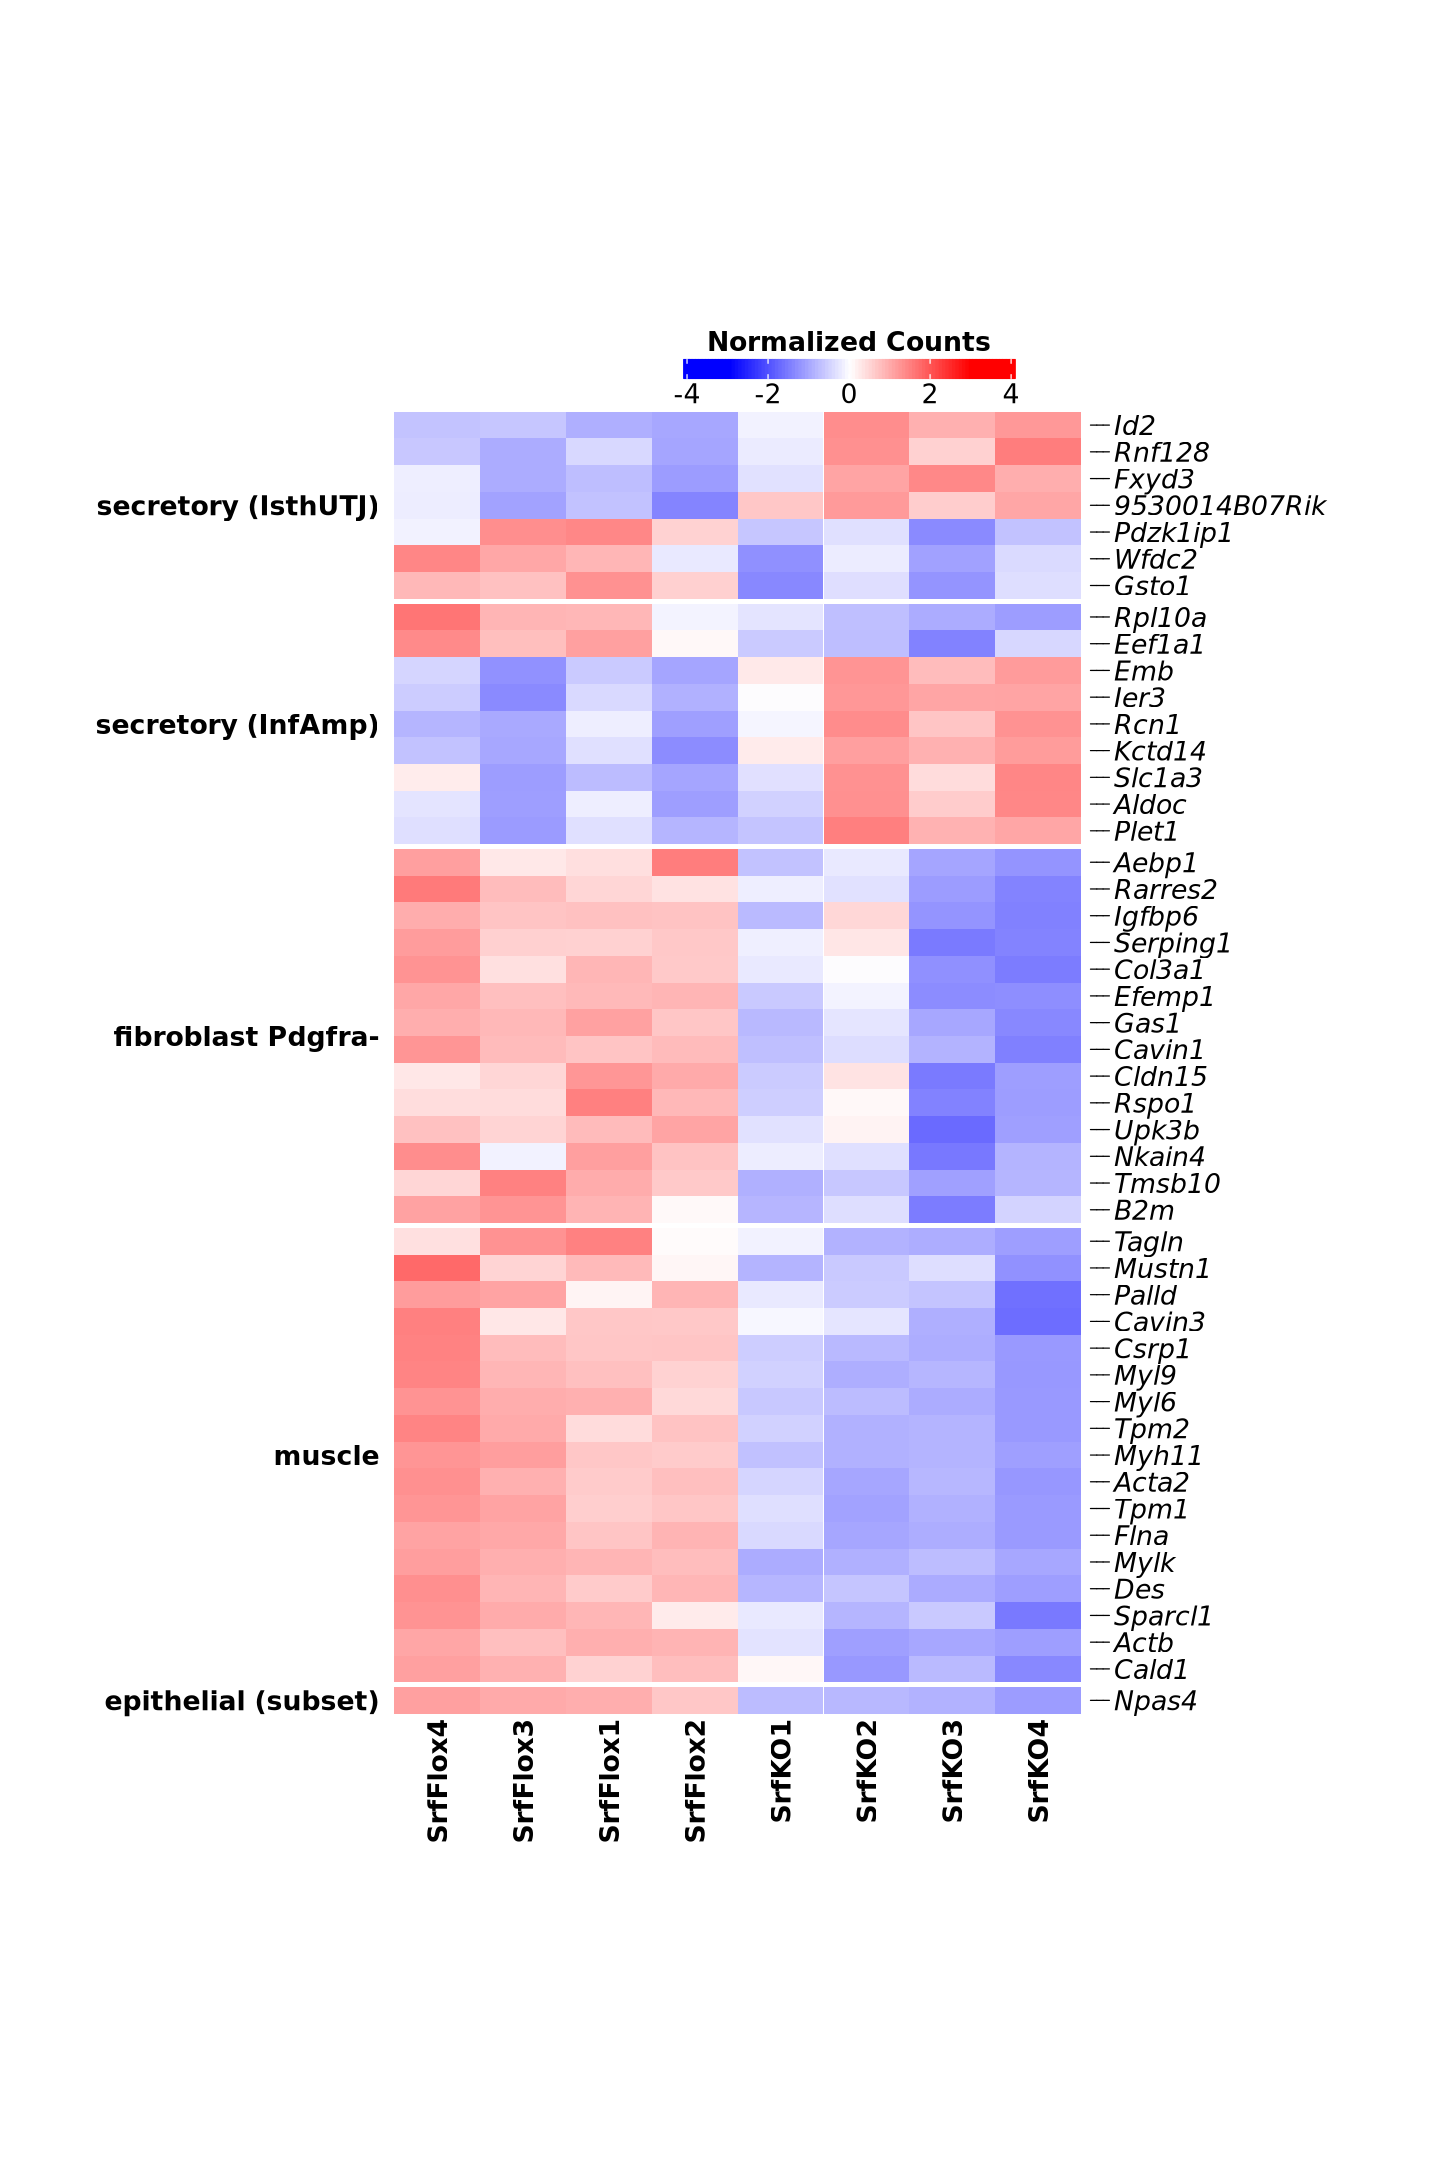

In [22]:
# draw again, now with right side annotation of specific genes, remove dendrogram
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 12, repr.plot.height = 18) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Aldoc", "Ier3", "Plet1", "Rcn1", "Kctd14", "Emb", "Eef1a1", "Slc1a3", 
                  "Rpl10a", "Fxyd3", "Wfdc2", "Id2", "Pdzk1ip1", "Rnf128", "Gsto1", "9530014B07Rik", 
                  "Igfbp6", "Upk3b", "Rarres2", "Aebp1", "Serping1", "Nkain4", "Cldn15", "Rspo1", "Gas1", "B2m", "Col3a1", "Efemp1", "Cavin1", "Tmsb10", 
                  "Acta2", "Tagln", "Myl9", "Tpm2", "Tpm1", "Myl6", "Mustn1", "Csrp1", "Flna", "Sparcl1", "Myh11", "Mylk", "Des", "Cald1", "Cavin3", "Palld", "Actb", 
                  "Npas4"
                  )        
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(30, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = FALSE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

options(saved) # restore old settings


Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


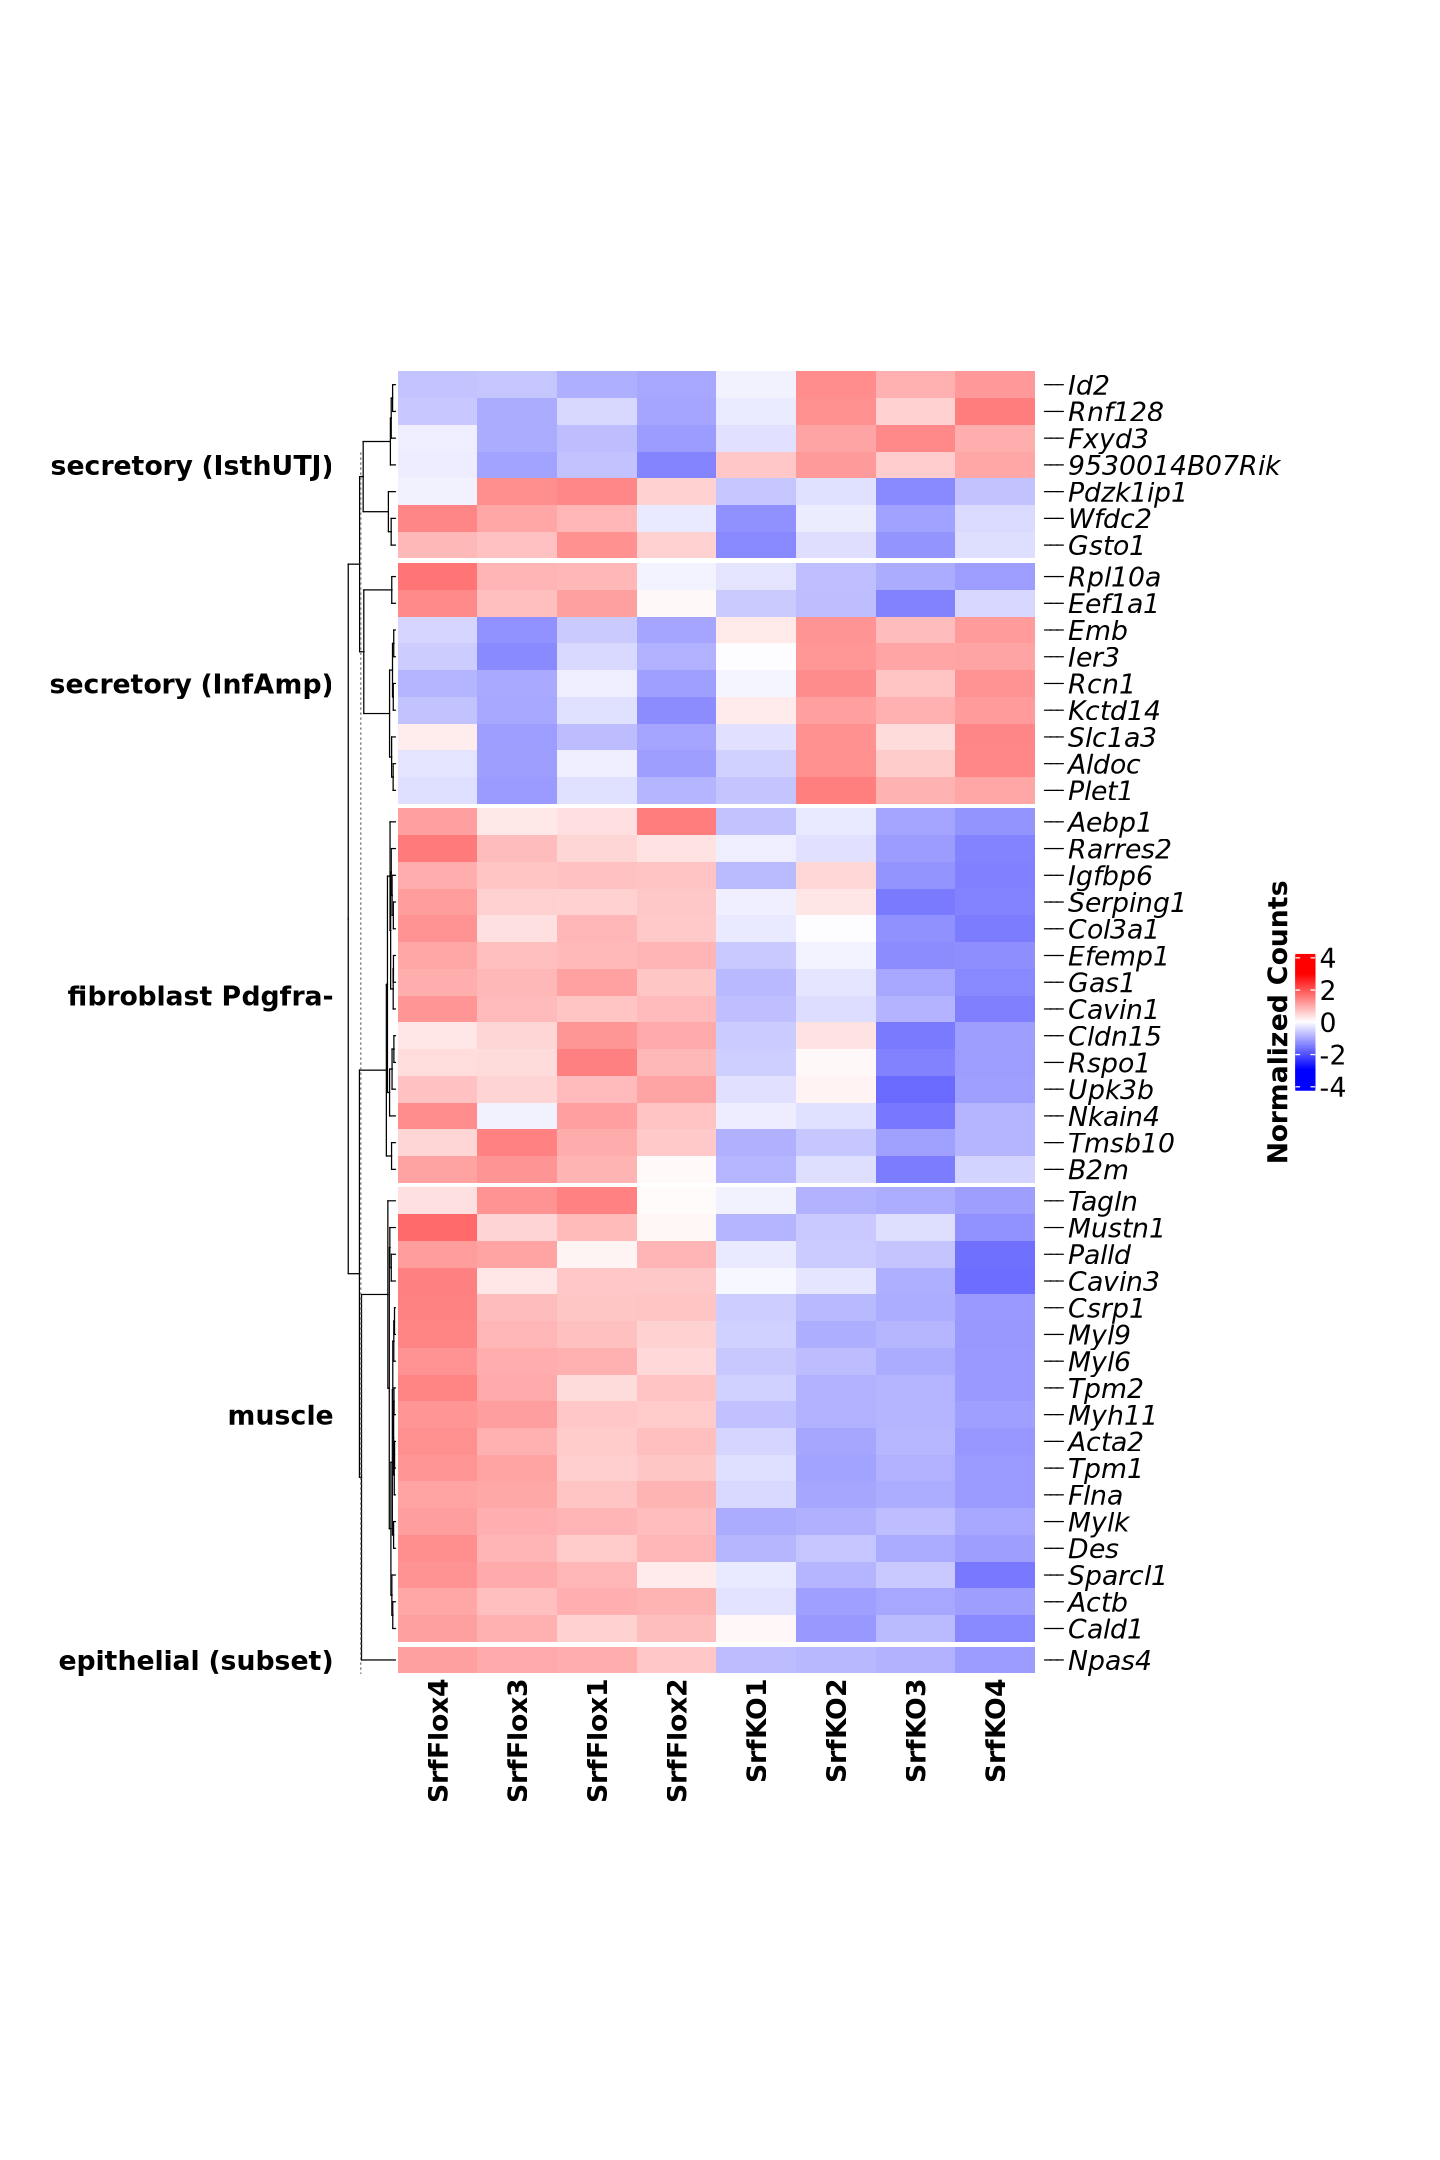

In [25]:
# draw again, now with right side annotation of specific genes, move legend, modify gene selections
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 12, repr.plot.height = 18) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Aldoc", "Ier3", "Plet1", "Rcn1", "Kctd14", "Emb", "Eef1a1", "Slc1a3", 
                  "Rpl10a", "Fxyd3", "Wfdc2", "Id2", "Pdzk1ip1", "Rnf128", "Gsto1", "9530014B07Rik", 
                  "Igfbp6", "Upk3b", "Rarres2", "Aebp1", "Serping1", "Nkain4", "Cldn15", "Rspo1", "Gas1", "B2m", "Col3a1", "Efemp1", "Cavin1", "Tmsb10", 
                  "Acta2", "Tagln", "Myl9", "Tpm2", "Tpm1", "Myl6", "Mustn1", "Csrp1", "Flna", "Sparcl1", "Myh11", "Mylk", "Des", "Cald1", "Cavin3", "Palld", "Actb", 
                  "Npas4"
                  )    
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(30, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "vertical",
    legend_width = unit(7, "cm"),
    title_position = "leftcenter-rot",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "right")

options(saved) # restore old settings


In [27]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /ddn/gs1/home/marquardtrm/miniforge3/envs/r431/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
[1] cluster_2.1.8.1       circlize_0.4.16       ComplexHeatmap_2.18.0

loaded via a namespace (and not attached):
 [1] crayon_1.5.3        vctrs_0.6.5         doParallel_1.0.17  
 [